# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** 

Ссылка на исходный датасет:

[prithivMLmods/OpenDetection-15K-Dense-v2.0](https://huggingface.co/datasets/prithivMLmods/OpenDetection-15K-Dense-v2.0)

**Источники кода:**

В 2.1 воспользовался кодом с семинара 5-6 для forward_hook. Адаптировал его под задание

In [1]:
# датасет с HF, а разбиение делал с помощью этой библиотеки, adjustText для красивого графика

%pip install -q datasets iterative-stratification adjustText

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.216, torch 2.11.0+cu130, device: Tesla T4


In [3]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = set()     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [4]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [5]:
import time


WEIGHTS = 'yolo26s.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
# ваш код

model_sha256 = hashlib.sha256(weights_path.read_bytes()).hexdigest()

size_mb = round(weights_path.stat().st_size / (1024 * 1024), 2)
params = sum(p.numel() for p in model_coco.model.parameters())

n_runs = 15
input = torch.zeros((1, 3, IMGSZ, IMGSZ), dtype=torch.float32, device=DEVICE)
times = np.zeros(n_runs)

for i in range(n_runs):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    
    _ = model_coco(input, verbose=False)
    
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    times[i] = (time.perf_counter() - start) * 1000

MODEL_INFO = {
    'ultralytics': ultralytics.__version__, 
    'weights': WEIGHTS,
    'sha256': model_sha256,
    'size_mb': size_mb,
    'params': params, 
    'n_classes_coco': len(model_coco.names), 
    'latency_ms': round(np.mean(times),2),
}

In [6]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26s.pt',
 'sha256': '646f8bc3fe0a656803d95c294f7852321748cb29d13466a1af8862e2db384a1b',
 'size_mb': 19.48,
 'params': 10009784,
 'n_classes_coco': 80,
 'latency_ms': np.float64(366.25)}

**Ответ:** 

На семинаре использовали версию n, поэтому решил попробовать версию s, немного покруче и потяжелее. В абляции справнил их, результаты там. Она достаточно маленькая, на CPU гоняется быстро (я писал код локально, на каггле только прогоны делал и эксперименты), быстро обучается на наших мощностях, да и в целом, ее достаточно, я думаю, для нашей задачи

По таблице Ultralytics у YOLO26n 2.4 млн параметров и mAP50-95 на COCO 40.9, а у YOLO26s - 9.5 млн и 48.6. Задержка на T4 с TensorRT при размере входа 640 - 1.7 мс и 2.5 мс соотв. То есть s тяжелее и медленнее, но качество на COCO выше

Код и обученные веса Ultralytics по умолчанию распространяются под AGPL-3.0

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [7]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    # ваш код

    n_params_backbone = sum(
        p.numel() 
        for layer in layers[:n_backbone]
        for p in layer.parameters()
    )
    n_params_neck = sum(
        p.numel() 
        for layer in layers[n_backbone:-1]
        for p in layer.parameters()
    )
    n_params_head = sum(p.numel() for p in layers[-1].parameters())

    return {
        'backbone': n_params_backbone,
        'neck': n_params_neck,
        'head': n_params_head
    }


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    # ваш код
    device = next(det_model.parameters()).device
    dummy = torch.zeros(1, 3, imgsz, imgsz, dtype=torch.float32, device=device)
    layers = det_model.model
    in_shape = []

    detection_layer = layers[-1]
    hook = detection_layer.register_forward_hook(
        lambda m, inp, out: in_shape.extend(tuple(t.shape) for t in inp[0])
    )

    with torch.no_grad():
        det_model.eval()
        output = det_model(dummy)

    hook.remove()

    return in_shape, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [8]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '5,441,984 (54%)', 'neck': '3,574,016 (36%)', 'head': '993,784 (10%)'} total 10,009,784
на входе Detect: [(1, 128, 80, 80), (1, 256, 40, 40), (1, 512, 20, 20)]


In [9]:
# ваш код
shapes(out)

[(1, 84, 8400),
 {'one2many': {'boxes': (1, 4, 8400),
   'scores': (1, 80, 8400),
   'feats': [(1, 128, 80, 80), (1, 256, 40, 40), (1, 512, 20, 20)]},
  'one2one': {'boxes': (1, 4, 8400),
   'scores': (1, 80, 8400),
   'feats': [(1, 128, 80, 80), (1, 256, 40, 40), (1, 512, 20, 20)]}}]

**Ответ:** 

Задача Backbone - извлечь из изображения признаки. Мы уменьшаем вход сверткой со stride=2 каждый раз в 2 раза, тем самым последние карты признаков содержат информацию о картинке в целом (P5), P3 - это достаточно детализированная карта (в 2**3 раза уменьшили размеры входа), она содержит достаточно точную информацию о позициях объектов, но не о глобальной структуре. P4 - что-то среднее. Все эти карты признаков мы подаем в neck - там их объединяем с входами из глубоких слоев после SPPF и CSPA в блоке, называемом FPN (feature pyramid network). так информация о глобальном содержании входа распространяется и на точные карты признаков

Дальше head получает карты трёх масштабов и для каждой позиции предсказывает координаты бокса и оценки классов. Детектор называется anchor-free, потому что он не использует заранее заданные формы ббоксов: координаты предсказываются относительно позиций на карте признаков

При входе 640×640 размеры трёх карт - 80×80, 40×40 и 20×20. Всего получается 80**2 + 40**2 + 20**2 = 8400 позиций

Ветка one2many обучается на нескольких подходящих предсказаниях для одного объекта, а one2one примерно на одном. За счёт второй ветки модель учится выдавать меньше дублей и может работать без NMS

Доли параметров: backbone 54%, neck 36%, head 10%

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [10]:
import hashlib
import json
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

from adjustText import adjust_text
from datasets import load_dataset
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

In [11]:
# ваш код
@dataclass(frozen=True)
class DataStats:
    class_names: tuple[str, ...]
    class_counts: np.ndarray
    image_fractions: np.ndarray
    mean_box_sizes: np.ndarray
    mean_boxes_per_image: float
    num_classes: int
    num_images: int
    boxes_per_image: np.ndarray


def get_dataset_stats(source: list[dict], class_names: list[str]) -> DataStats:
    n = len(class_names)
    counts = np.zeros(n, dtype=int)
    images_per_class = np.zeros(n, dtype=int)
    sizes = np.zeros((n, 2), dtype=float)

    per_image = np.array([len(r["labels"]) for r in source], dtype=int)
    for record in source:
        labels = record["labels"]
        boxes = record["boxes"]
        counts += np.bincount(labels, minlength=n)
        images_per_class[np.unique(labels)] += 1
        for label, box in zip(labels, boxes):
            sizes[label] += box[2:] - box[:2]

    means = np.full((n, 2), np.nan)
    present = counts > 0
    means[present] = sizes[present] / counts[present, None]

    return DataStats(
        class_names=tuple(class_names),
        class_counts=counts,
        image_fractions=images_per_class / len(source) if source else images_per_class.astype(float),
        mean_box_sizes=means,
        mean_boxes_per_image=float(per_image.mean()) if source else 0.0,
        num_classes=n,
        num_images=len(source),
        boxes_per_image=per_image,
    )


def vizualize_split_stats(
    split_stats: dict[str, DataStats],
    classes: list[str] | tuple[str, ...],
    show_class_counts: bool = True,
    show_box_sizes: bool = True,
) -> None:
    if any(stats.class_names != tuple(classes) for stats in split_stats.values()):
        raise ValueError("порядок классов должен совпадать")

    n_plots = int(show_class_counts) + int(show_box_sizes)
    if not n_plots:
        return

    fig, axes = plt.subplots(
        1,
        n_plots,
        figsize=(10 * n_plots, 12),
        squeeze=False,
    )
    axes = axes[0]
    texts = []

    if show_class_counts:
        ax = axes[0]

        total_counts = sum(
            (stats.class_counts for stats in split_stats.values()),
            start=np.zeros(len(classes), dtype=int),
        )
        order = np.argsort(-total_counts)
        sorted_classes = [classes[i] for i in order]

        positions = np.arange(len(classes))
        width = 1 / (len(split_stats) + 1)

        for i, (name, stats) in enumerate(split_stats.items()):
            ax.barh(
                positions + i * width,
                stats.class_counts[order],
                height=width,
                label=name,
            )

        ax.set_yticks(
            positions + (len(split_stats) - 1) * width / 2,
            sorted_classes,
        )
        ax.invert_yaxis()
        ax.set_xscale("log")
        ax.set_xlabel("Число объектов (log шкала)")
        ax.set_title("Частоты классов")
        ax.grid(axis="x", alpha=0.25)
        ax.legend()

    if show_box_sizes:
        ax = axes[int(show_class_counts)]

        for name, stats in split_stats.items():
            sizes = stats.mean_box_sizes

            points = ax.scatter(
                sizes[:, 0],
                sizes[:, 1],
                label=name,
                alpha=0.8,
            )
            color = points.get_facecolor()[0]

            for class_name, size in zip(classes, sizes):
                if np.isnan(size).any():
                    continue

                texts.append(
                    ax.text(size[0], size[1], class_name, fontsize=8, color=color)
                )

        ax.set_xlabel("Средняя ширина, px")
        ax.set_ylabel("Средняя высота, px")
        ax.set_title("Средние размеры боксов")
        ax.grid(alpha=0.25)
        ax.legend()

    fig.tight_layout()

    if texts:
        adjust_text(
            texts,
            ax=ax,
            arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.5},
        )

    plt.show()


def vizualize_stats(
    stats: DataStats,
    title: str = "Датасет",
    show_class_counts: bool = True,
    show_box_sizes: bool = True,
) -> None:
    vizualize_split_stats(
        {title: stats}, stats.class_names, show_class_counts, show_box_sizes
    )


In [12]:
def split_dataset(
    source: list[dict],
    num_classes: int,
    val_ratio: float = 0.15,
    test_ratio: float = 0.15,
    seed: int = 42,
) -> dict[str, list[dict]]:

    train_ratio = 1 - val_ratio - test_ratio
    if min(train_ratio, val_ratio, test_ratio) <= 0:
        raise ValueError("все три доли должны быть положительными")

    labels = np.zeros((len(source), num_classes), dtype=int)
    for i, record in enumerate(source):
        labels[i, record["labels"]] = 1

    first = MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=val_ratio + test_ratio,
        random_state=seed,
    )
    ((train_idx, rest_idx),) = first.split(labels, labels)

    second = MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=test_ratio / (val_ratio + test_ratio),
        random_state=seed,
    )
    ((val_idx, test_idx),) = second.split(labels[rest_idx], labels[rest_idx])

    return {
        "train": [source[i] for i in train_idx],
        "val": [source[i] for i in rest_idx[val_idx]],
        "test": [source[i] for i in rest_idx[test_idx]],
    }


def prepare_dataset(
    data_root: Path,
    subset_size: int = 2000,
    min_class_image_count: int = 100,
    seed: int = 42,
) -> tuple[list[dict], list[str]]:

    raw = load_dataset("prithivMLmods/OpenDetection-15K-Dense-v2.0", split="train")
    objects = [json.loads(x) if isinstance(x, str) else x for x in raw["objects"]]

    counts = Counter(
        label
        for image_objects in objects
        for label in {obj["label"] for obj in image_objects}
    )
    classes = sorted(name for name, count in counts.items() if count >= min_class_image_count)
    name2id = {name: i for i, name in enumerate(classes)}

    eligible = [
        i
        for i, image_objects in enumerate(objects)
        if image_objects and {obj["label"] for obj in image_objects} <= name2id.keys()
    ]

    image_dir = data_root / "source_images"
    image_dir.mkdir(parents=True, exist_ok=True)

    source: list[dict] = []
    seen = set()

    clipped_count = invalid_count = duplicate_count = 0
    indexes = np.random.default_rng(seed).permutation(eligible)

    for index in indexes:
        if len(source) == subset_size:
            break

        index = int(index)
        image = raw[index]["image"].convert("RGB")

        hash = hashlib.sha256(image.tobytes() + str(image.size).encode()).hexdigest()
        if hash in seen:
            duplicate_count += 1
            continue
        seen.add(hash)

        width, height = image.size
        boxes, labels = [], []
        for obj in objects[index]:
            box = np.asarray(obj["bbox"], dtype=float)
            if box.shape != (4,) or not np.isfinite(box).all():
                invalid_count += 1
                continue

            clipped = np.clip(box, [0, 0, 0, 0], [width, height, width, height])
            clipped_count += int(not np.array_equal(box, clipped))
            if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
                invalid_count += 1
                continue

            boxes.append(clipped)
            labels.append(name2id[obj["label"]])

        path = image_dir / f"{index:06d}.jpg"
        image.save(path, format="JPEG", quality=95)
        source.append(
            {
                "image": path,
                "width": width,
                "height": height,
                "boxes": np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                "labels": np.asarray(labels, dtype=np.int64),
            }
        )

    if len(source) < subset_size:
        raise ValueError(f"Удалось выбрать только {len(source)} изображений")

    print(f"Обрезано боксов: {clipped_count}")
    print(f"Удалено некорректных боксов: {invalid_count}")
    print(f"Дубликатов: {duplicate_count}")
    return source, classes

In [13]:
source, CLASSES = prepare_dataset(DATA_ROOT, seed=42)
records = split_dataset(source, len(CLASSES), seed=42)

DATASET_NAME = (
    "OpenDetection-15K-Dense-v2.0; https://huggingface.co/datasets/"
    "prithivMLmods/OpenDetection-15K-Dense-v2.0; Apache-2.0"
)

README.md:   0%|          | 0.00/3.71k [00:00<?, ?B/s]

data/train-00000-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  492MB            

data/train-00000-of-00014.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  487MB            

data/train-00001-of-00014.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  486MB            

... (21 outputs left out)

data/train-00013-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  494MB            

data/train-00013-of-00014.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14911 [00:00<?, ? examples/s]

Обрезано боксов: 0
Удалено некорректных боксов: 15
Дубликатов: 0


In [14]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 1399, 'val': 302, 'test': 299}

train: 1399 изображений, 6577 объектов, 4.70 бокса на изображение
val: 302 изображений, 1474 объектов, 4.88 бокса на изображение
test: 299 изображений, 1402 объектов, 4.69 бокса на изображение

Доля изображений с каждым классом:
person: train: 93.8% | val: 93.0% | test: 94.0%
car: train: 9.3% | val: 9.3% | test: 9.4%
handbag: train: 9.3% | val: 8.9% | test: 9.4%
dog: train: 7.4% | val: 7.3% | test: 7.7%
chair: train: 7.4% | val: 7.3% | test: 7.4%
bottle: train: 4.9% | val: 4.6% | test: 5.0%
backpack: train: 4.3% | val: 4.3% | test: 4.3%
sports ball: train: 4.2% | val: 4.0% | test: 4.3%
bicycle: train: 4.1% | val: 4.0% | test: 4.3%
cup: train: 3.4% | val: 3.3% | test: 3.3%
truck: train: 3.2% | val: 3.0% | test: 3.3%
umbrella: train: 2.7% | val: 2.6% | test: 2.7%
bench: train: 2.5% | val: 2.3% | test: 2.7%
motorcycle: train: 2.4% | val: 2.3% | test: 2.7%
boat: train: 2.1% | val: 2.0% | test: 2.0%
skateboard: train: 1.7% | val: 1.7% | test: 1.7%
traffic light: train: 1.6% | val: 1.7% | te

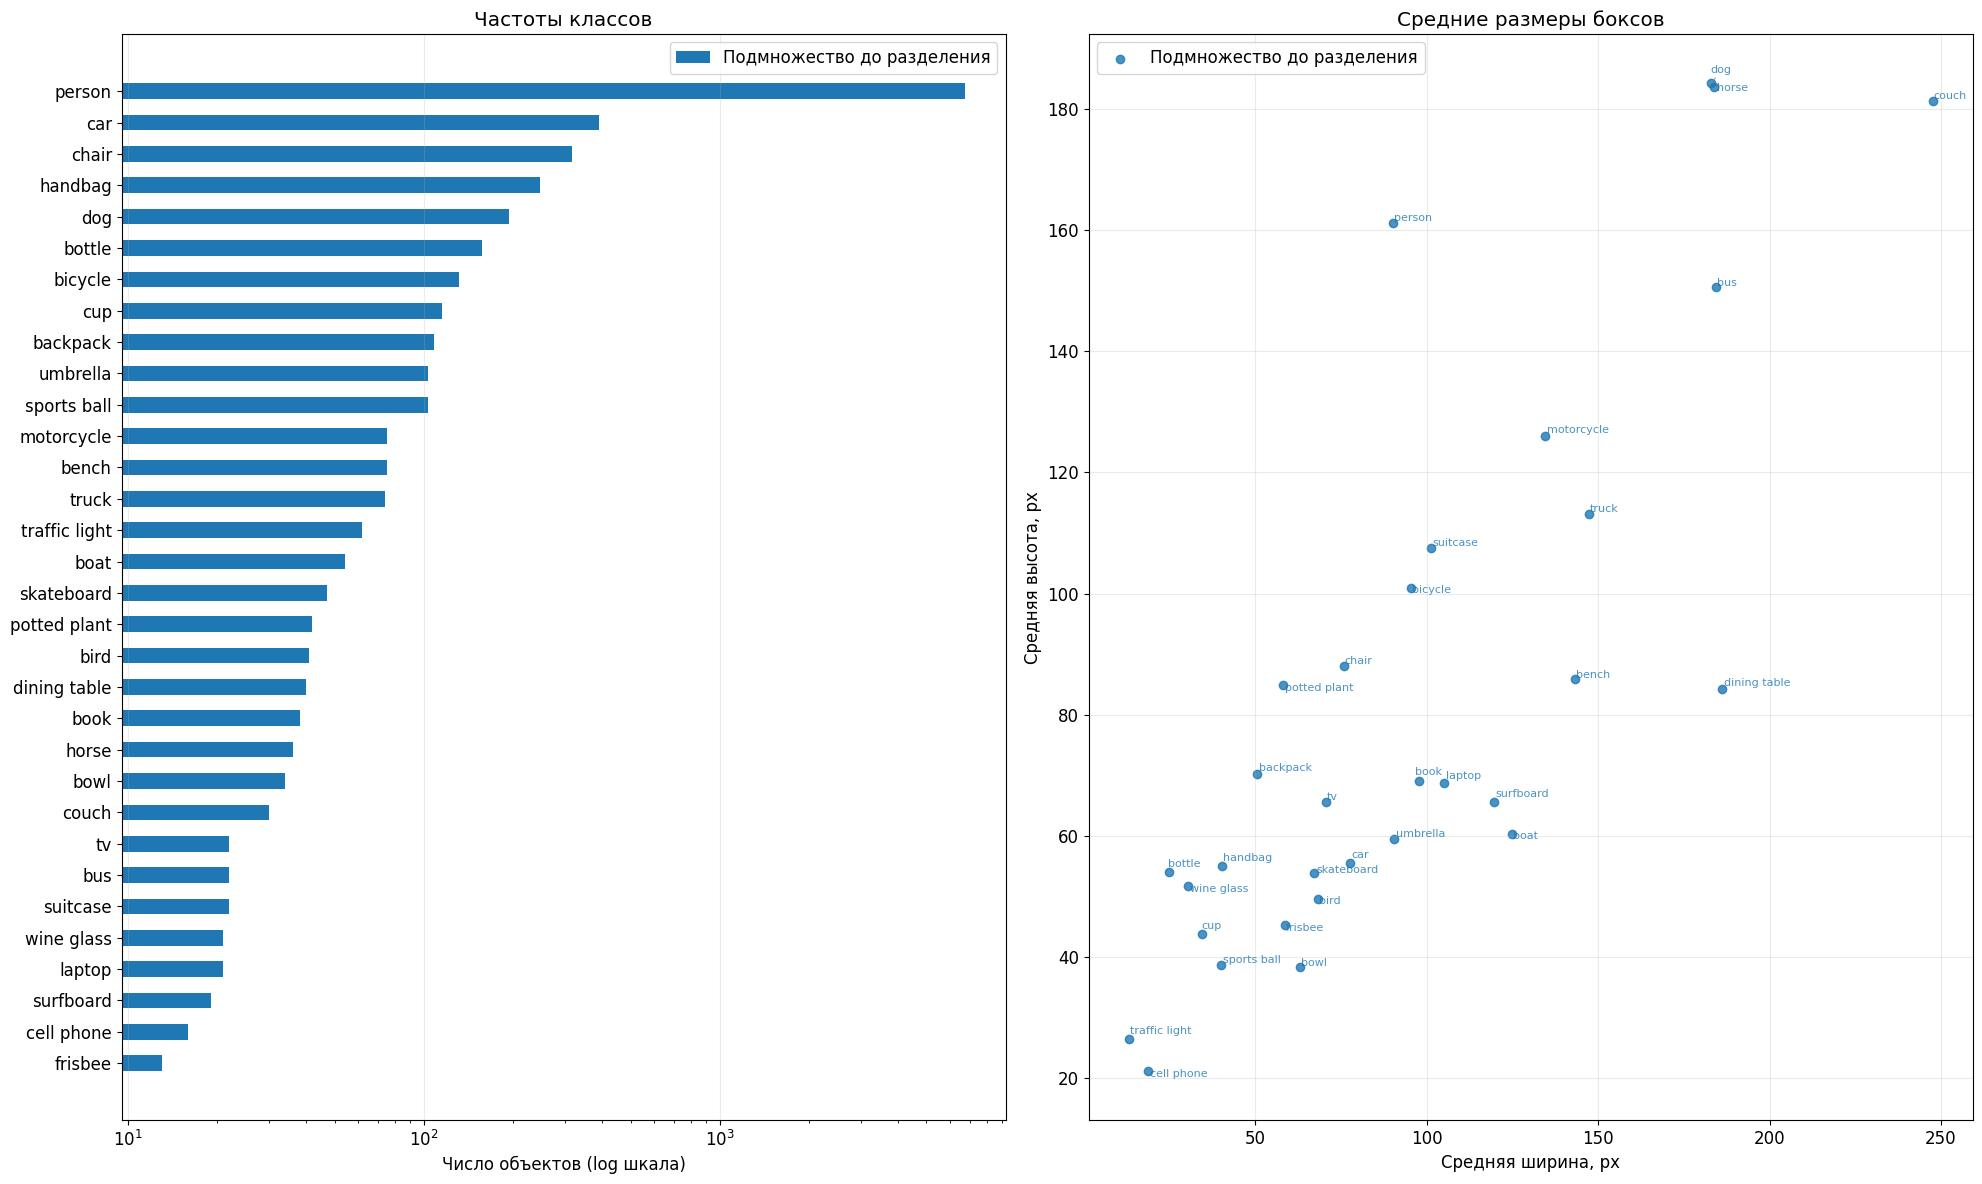

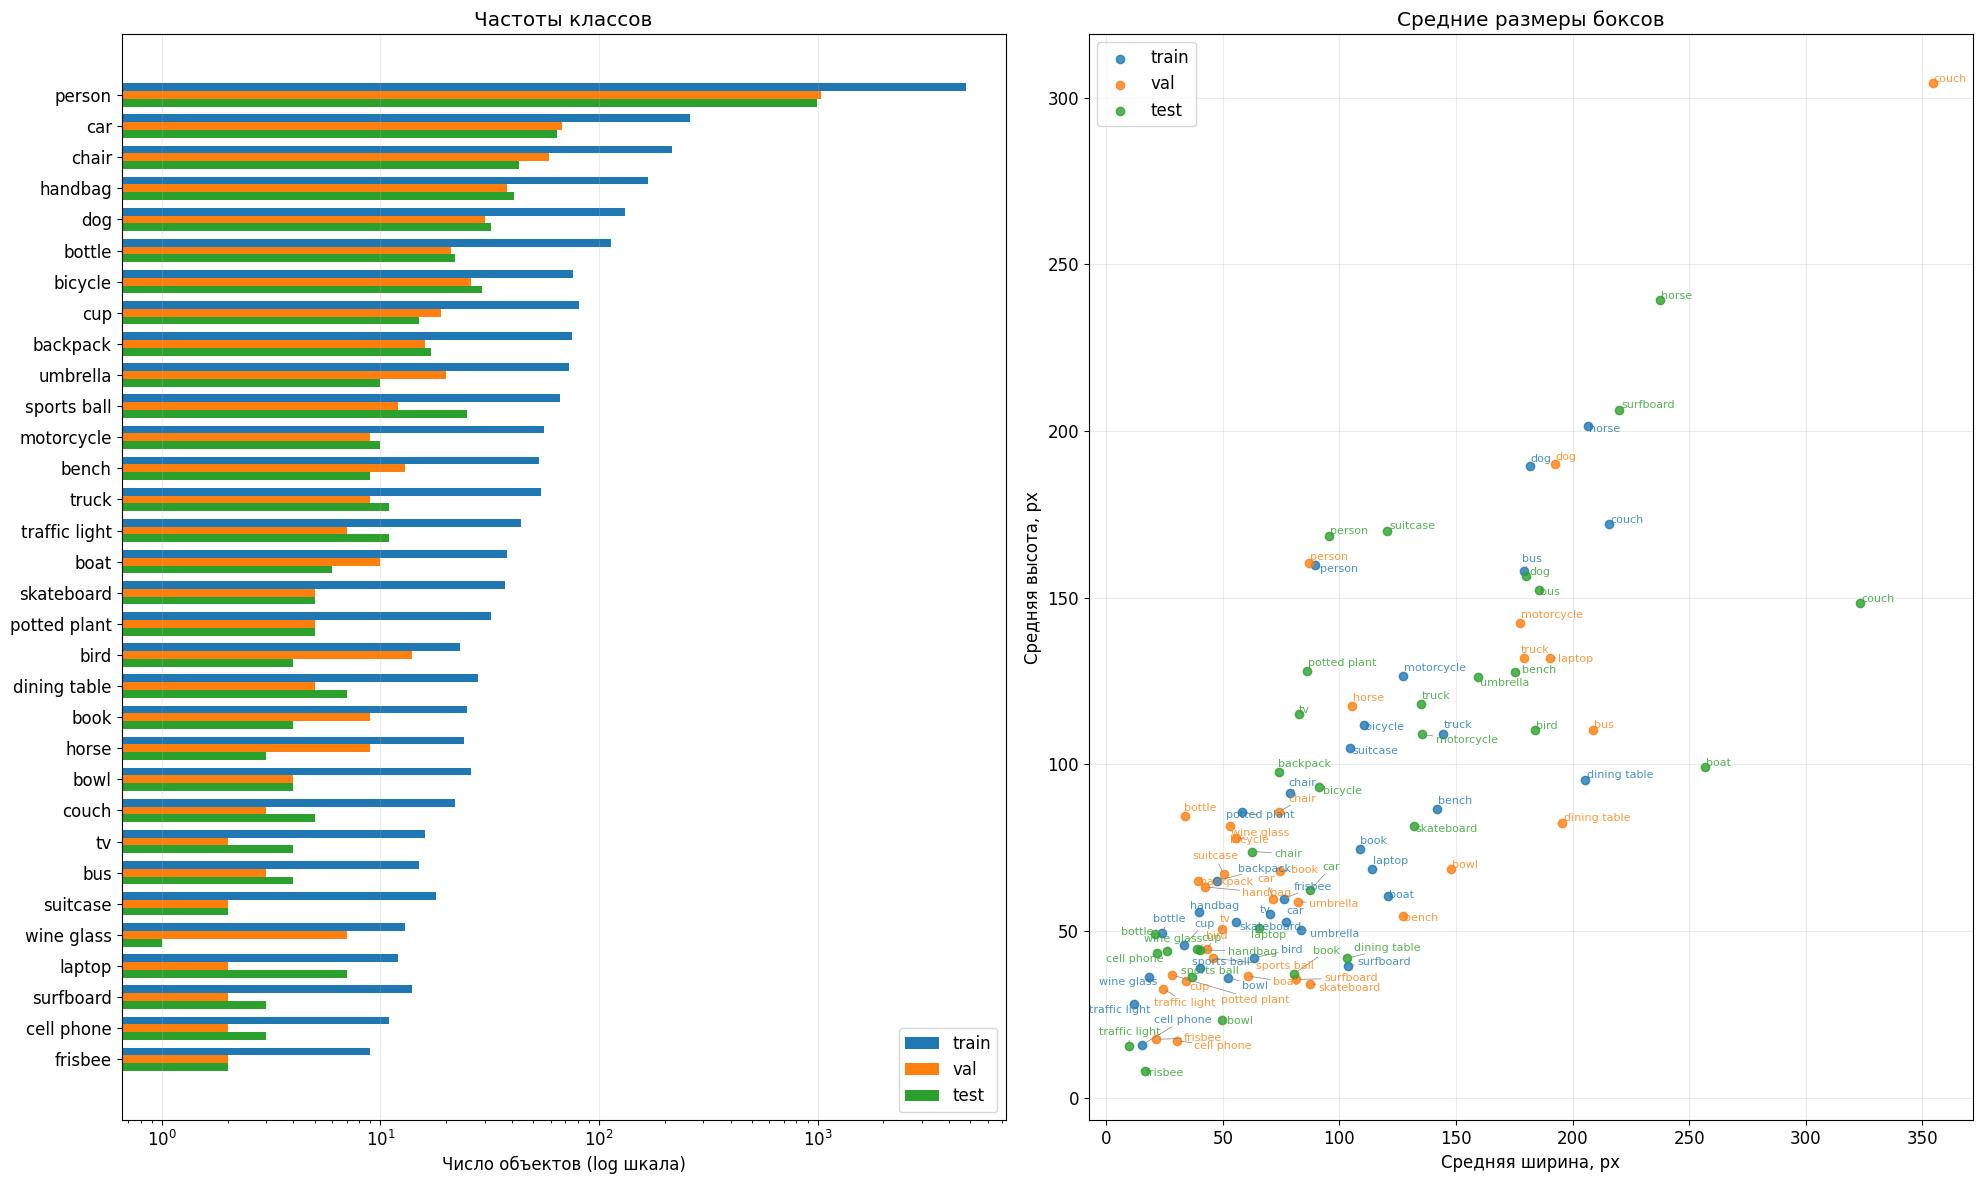

In [15]:
# ваш код
all_stats = get_dataset_stats(source, CLASSES)
split_stats = {
    name: get_dataset_stats(recs, CLASSES)
    for name, recs in records.items()
}

for name, stats in split_stats.items():
    print(
        f"{name}: {stats.num_images} изображений, "
        f"{stats.class_counts.sum()} объектов, "
        f"{stats.mean_boxes_per_image:.2f} бокса на изображение"
    )

print("\nДоля изображений с каждым классом:")

order = np.argsort(-all_stats.image_fractions)

for i in order:
    fractions = " | ".join(
        f"{name}: {stats.image_fractions[i]:.1%}"
        for name, stats in split_stats.items()
    )
    print(f"{CLASSES[i]}: {fractions}")

vizualize_stats(all_stats, title="Подмножество до разделения")
vizualize_split_stats(split_stats, CLASSES)

**Ответ:** 

Датасет содержит различные кадры и картинки с размеченными классами людей, автомобилей и тд. Разметка создана под детекцию, исходный формат:
```json
{
    "source_row": 10243, 
    "objects": [
        {"label": "dog", "label_id": 18, "score": 0.9211, "bbox": [159, 224, 243, 312]}, 
        ...
        {"label": "person", "label_id": 1, "score": 0.8962, "bbox": [234, 97, 294, 219]}
    ]
}
```

Лицензия - Apache 2.0

Взял подмножество из 2000 изображений. Выбирал изображения случайно с фиксированным seed, оставляя классы, которые встречались хотя бы на 100 изображениях исходного датасета. Затем разделил данные на train, val и test в пропорции примерно 70/15/15. Дубликаты изображений, боксы с некорректными координатами при подготовке удалял, боксы за границами изображения обрезал

На графиках видно, что есть много классов с очень малой долей. Сильно лидирует person, остальных сильно меньше. Много классов с малыми боксами относительно других: ceil_phone, traffic_lights, cup, bowl и тп. Также есть и большие по типу couch, horse, bus (неожиданно dog - их крупным планом снимали). Удалил 15 дубликатов

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [16]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    # ваш код
    n_bboxes, n_coords = boxes.shape
    n_labels, = labels.shape
    if n_bboxes == 0:
        return ''
    if n_coords != 4: 
        raise ValueError(f"boxes должны быть shape = (n, 4), но их shape = ({n_bboxes, n_coords})")
    if n_bboxes != n_labels:
        raise ValueError(f"кол-во boxes {n_bboxes} должно совпадать с кол-вом labels {n_labels}")
    
    yolo_boxes = np.stack(
        [(boxes[:, 2] + boxes[:, 0]) / (2 * width),
        (boxes[:, 3] + boxes[:, 1]) / (2 * height),
        (boxes[:, 2] - boxes[:, 0]) / width,
        (boxes[:, 3] - boxes[:, 1]) / height],
        axis=1
    )

    text = "\n".join([
        f"{labels[i]} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}"
        for i, (cx, cy, w, h) in enumerate(yolo_boxes)
    ])

    return text

def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    # ваш код
    if text == "":
        return np.zeros((0, 4)), np.zeros(0, dtype=np.int64)

    try:
        rows = text.strip("\n").split("\n")
    except Exception as e:
        print(f"не получилось запарсить текст по окончанию \ n")

    n = len(rows)
    boxes = [[0.0, 0.0, 0.0, 0.0]] * n
    labels = np.zeros(n, dtype=np.int64)

    for i, row in enumerate(rows):
        try:
            items = tuple(map(float, row.split(' ')))
            cls, cx, cy, w, h = items
            x1 = (cx - w / 2) * width
            y1 = (cy - h / 2) * height
            x2 = (cx + w / 2) * width
            y2 = (cy + h / 2) * height

            boxes[i] = [x1, y1, x2, y2]
            labels[i] = cls
        except Exception as e:
            print(f"не получилось запарсить строку {i}: '{row}':\n", e)

    return np.array(boxes, dtype=np.float32), labels

<>:37: SyntaxWarning: invalid escape sequence '\ '
<>:37: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_50/869652990.py:37: SyntaxWarning: invalid escape sequence '\ '
  print(f"не получилось запарсить текст по окончанию \ n")


In [17]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [18]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    # ваш код
    images_dir = Path(YOLO_ROOT / "images" / split)
    labels_dir = Path(YOLO_ROOT / "labels" / split)
    images_dir.mkdir(exist_ok=True, parents=True)
    labels_dir.mkdir(exist_ok=True, parents=True)

    used_names = set()

    for i, rec in enumerate(recs):
        image_path = Path(rec['image'])
        if image_path.stem in used_names:
            raise ValueError(f"повтор изображения: {image_path.stem}")
        used_names.add(image_path.stem)

        shutil.copy2(image_path, images_dir / image_path.name)
        label = to_yolo(
            rec["boxes"],
            rec["labels"],
            rec["width"],
            rec["height"],
        )

        label_path = labels_dir / f"{image_path.stem}.txt"
        label_path.write_text(label, encoding="utf-8")


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /kaggle/working/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: backpack
  1: bench
  2: bicycle
  3: bird
  4: boat
  5: book
  6: bottle
  7: bowl
  8: bus
  9: car
  10: cell phone
  11: chair
  12: couch
  13: cup
  14: dining table
  15: dog
  16: frisbee
  17: handbag
  18: horse
  19: laptop
  20: motorcycle
  21: person
  22: potted plant
  23: skateboard
  24: sports ball
  25: suitcase
  26: surfboard
  27: traffic light
  28: truck
  29: tv
  30: umbrella
  31: wine glass



In [19]:
# ваш код

def visualize_yolo(
    split: str,
    classes: list[str],
    recs: list[dict] | None = None,
    preds: list[dict] | None = None,
    n_images: int = 4,
    conf: float = 0.3
) -> None:
    images_dir = YOLO_ROOT / "images" / split
    labels_dir = YOLO_ROOT / "labels" / split

    if preds is not None:
        if recs is None or len(recs) != len(preds):
            raise ValueError("записи не соответствуют предсказаниям")

        preds_by_name = {
            Path(record["image"]).name: pred
            for record, pred in zip(recs, preds)
        }
    else:
        preds_by_name = {}

    image_paths = sorted(images_dir.glob("*.jpg"))

    if preds is not None:
        image_paths = [
            path for path in image_paths
            if path.name in preds_by_name
        ]

    rng = np.random.default_rng(SEED)
    indexes = rng.permutation(len(image_paths))[:n_images]
    image_paths = [image_paths[i] for i in indexes]
    if not image_paths:
        raise ValueError(f"подходящие изображения не найдены в {images_dir}")

    fig, axes = plt.subplots(
        1, len(image_paths),
        figsize=(7 * len(image_paths), 6),
        squeeze=False,
    )

    for ax, image_path in zip(axes[0], image_paths):
        label_path = labels_dir / f"{image_path.stem}.txt"

        image = Image.open(image_path)
        width, height = image.size
        ax.imshow(image.convert("RGB"))

        text = label_path.read_text(encoding="utf-8")
        boxes, labels = from_yolo(text, width, height)

        for box, label in zip(boxes, labels):
            x1, y1, x2, y2 = box
            ax.add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="lime", linewidth=2,
            ))
            ax.text(
                x1, y1, classes[int(label)], fontsize=9, color="black",
                bbox=dict(facecolor="lime", alpha=0.8, edgecolor="none"),
            )

        if preds is not None:
            pred = preds_by_name[image_path.name]

            for box, label, score in zip(pred["boxes"], pred["labels"], pred["scores"]):
                if score < conf:
                    continue

                x1, y1, x2, y2 = box
                ax.add_patch(Rectangle(
                    (x1, y1), x2 - x1, y2 - y1,
                    fill=False, edgecolor="red", linewidth=2, linestyle="--",
                ))
                ax.text(
                    x1, y2, f"{classes[int(label)]}: {score:.2f}",
                    fontsize=9, color="white",
                    bbox=dict(facecolor="red", alpha=0.8, edgecolor="none"),
                )

        ax.set_title(image_path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

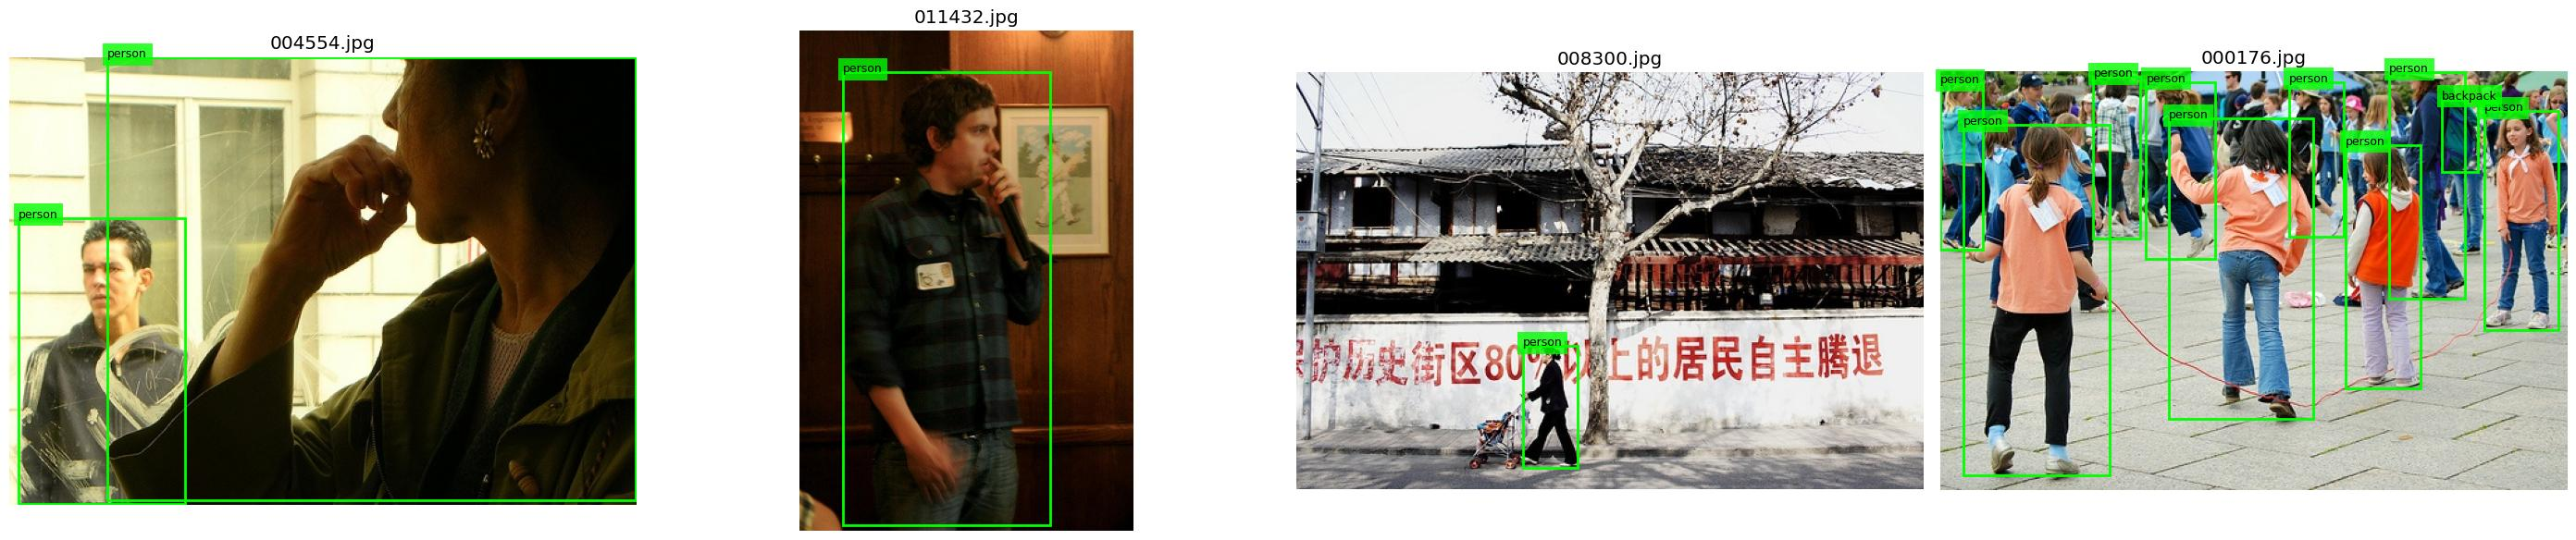

In [20]:
visualize_yolo("train", classes=CLASSES)

**Ответ:**

Тест туда-обратно проверяет, что после перевода боксов в формат YOLO и обратно координаты и классы примерно совпадают с исходными. Небольшая разница может возникнуть из-за округления

Такой тест не обязательно доказывает, что разметка правильная. А вот на картинке можно заметить, что боксы как то смещены, растянуты, не попадают на объекты или подписаны неправильным классом

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [21]:
# ваш код

COCO_TO_OUR_NAME = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck",
    8: "boat",
    9: "traffic light",
    13: "bench",
    14: "bird",
    16: "dog",
    17: "horse",
    24: "backpack",
    25: "umbrella",
    26: "handbag",
    28: "suitcase",
    29: "frisbee",
    32: "sports ball",
    36: "skateboard",
    37: "surfboard",
    39: "bottle",
    40: "wine glass",
    41: "cup",
    45: "bowl",
    56: "chair",
    57: "couch",
    58: "potted plant",
    60: "dining table",
    62: "tv",
    63: "laptop",
    67: "cell phone",
    73: "book",
}

our_name2id = {name: i for i, name in enumerate(CLASSES)}

coco2our = {
    coco_id: our_name2id[name]
    for coco_id, name in COCO_TO_OUR_NAME.items()
}
our2coco = {
    our_id: coco_id
    for coco_id, our_id in coco2our.items()
}

На всякий случай сверю:

In [22]:
assert set(COCO_TO_OUR_NAME.values()) == set(CLASSES)
assert all(
    model_coco.names[coco_id] == name
    for coco_id, name in COCO_TO_OUR_NAME.items()
)

print("Все классы сопоставлены:", len(coco2our))

Все классы сопоставлены: 32


In [23]:
model = YOLO(WEIGHTS)
coco_preds = predict_records(model, records[FINAL_SPLIT])

for i in range(len(coco_preds)):
    boxes = coco_preds[i]['boxes']
    labels = coco_preds[i]['labels']
    scores = coco_preds[i]['scores']

    our_labels = np.array([coco2our.get(id, -1) for id in labels])
    mask = (our_labels != -1).astype(np.bool)

    coco_preds[i]['boxes'] = boxes[mask]
    coco_preds[i]['labels'] = our_labels[mask]
    coco_preds[i]['scores'] = scores[mask]

coco_map50, coco_aps = evaluate_map50(
    preds=coco_preds, gts=records[FINAL_SPLIT], n_classes=len(CLASSES),
)

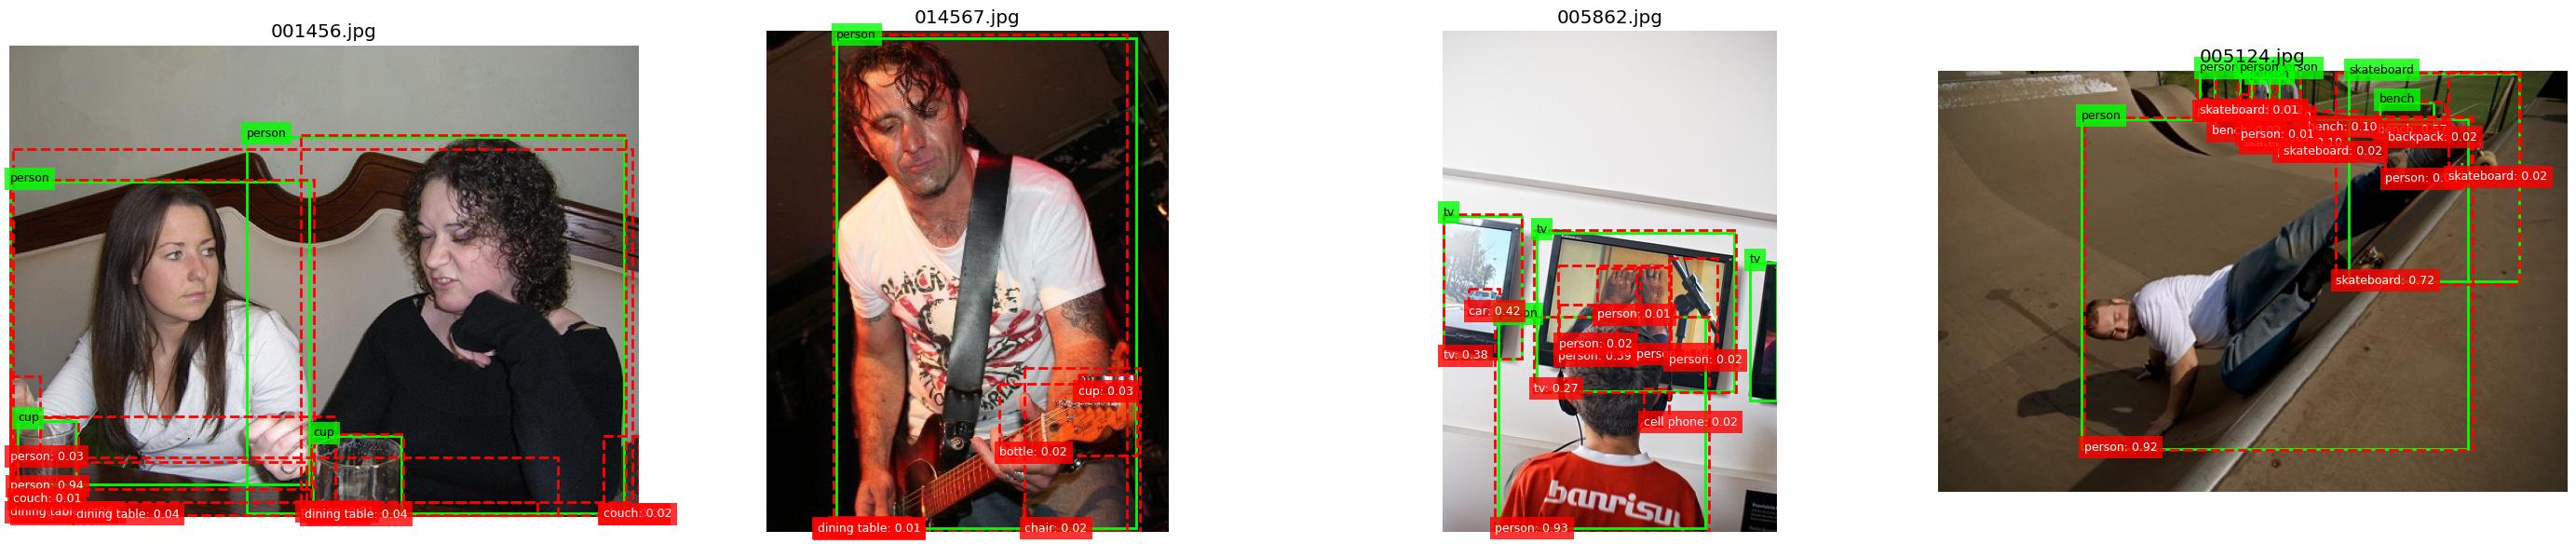

In [24]:
visualize_yolo(
    FINAL_SPLIT,
    classes=CLASSES,
    recs=records[FINAL_SPLIT],
    preds=coco_preds,
    conf=0.01
)

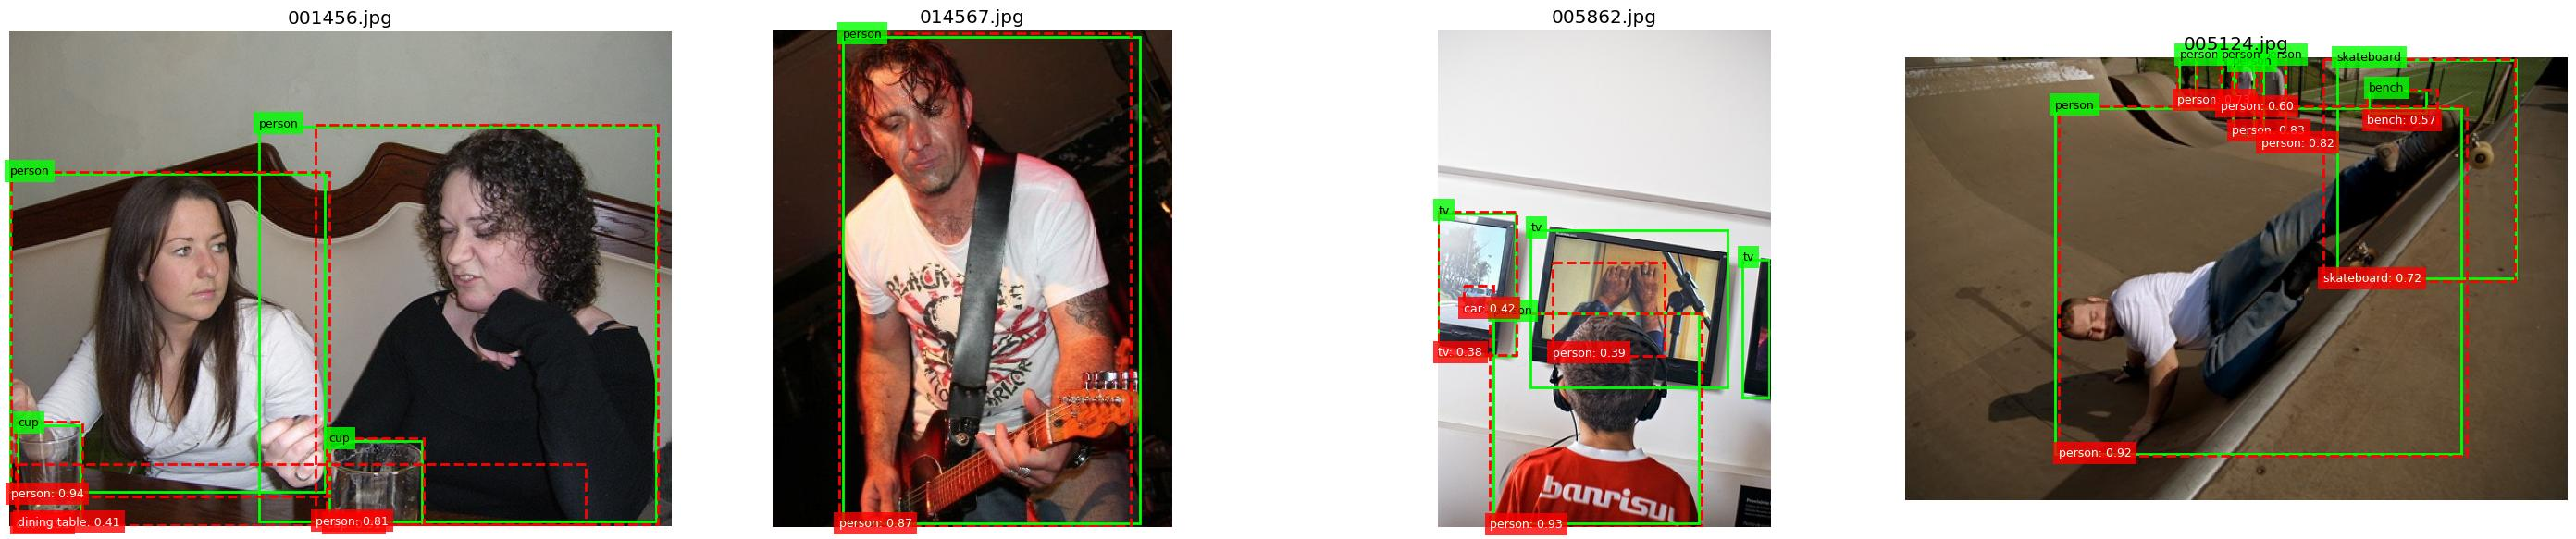

In [25]:
visualize_yolo(
    FINAL_SPLIT,
    classes=CLASSES,
    recs=records[FINAL_SPLIT],
    preds=coco_preds,
    conf=0.3
)

In [26]:
coco_map50

0.7104014365508231

In [27]:
import cv2

In [28]:
def get_mean_box_areas(recs: list[dict], n_classes: int) -> np.ndarray:
    areas_by_class = [[] for _ in range(n_classes)]

    for record in recs:
        image_area = record["width"] * record["height"]

        for box, label in zip(record["boxes"], record["labels"]):
            x1, y1, x2, y2 = box
            area = (x2 - x1) * (y2 - y1) / image_area
            areas_by_class[int(label)].append(area)

    return np.array([np.mean(areas) if areas else np.inf for areas in areas_by_class])


MEAN_BOX_AREAS = get_mean_box_areas(records["train"], len(CLASSES))
EDGE_THRESHOLD = 80
MIN_AREA = 0.005

In [29]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    # ваш код
    image = np.array(Image.open(image_path).convert("L"))
    height, width = image.shape

    grad_x = cv2.Sobel(image, cv2.CV_32F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(image, cv2.CV_32F, 0, 1, ksize=3)
    edges = cv2.magnitude(grad_x, grad_y)
    edges = (edges >= EDGE_THRESHOLD).astype(np.uint8)

    kernel = np.ones((5, 5), dtype=np.uint8)
    edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)
    n_components, _, components, _ = cv2.connectedComponentsWithStats(edges)

    boxes, labels, scores = [], [], []

    for x, y, box_width, box_height, _ in components[1:n_components]:
        area = box_width * box_height / (width * height)
        if area < MIN_AREA:
            continue

        differences = np.abs(MEAN_BOX_AREAS - area)
        label = int(np.argmin(differences))
        score = 1 - differences[label] / max(area, MEAN_BOX_AREAS[label])

        boxes.append([x, y, x + box_width, y + box_height])
        labels.append(label)
        scores.append(score)

    return {
        "boxes": np.array(boxes, dtype=np.float32).reshape(-1, 4),
        "labels": np.array(labels, dtype=np.int64),
        "scores": np.array(scores, dtype=np.float32),
    }

In [30]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)

import optuna


def objective(trial: optuna.Trial) -> float:
    # придется так сделать, т.к. нельзя ломать контракт heuristic_detect
    global EDGE_THRESHOLD, MIN_AREA

    EDGE_THRESHOLD = trial.suggest_int("edge_threshold", 30, 300)
    MIN_AREA = trial.suggest_float("min_area", 0.0005, 0.05, log=True)

    preds = [heuristic_detect(record["image"]) for record in records["train"]]
    map50, _ = evaluate_map50(preds, records["train"], len(CLASSES))
    return map50


sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=20)

EDGE_THRESHOLD = study.best_params["edge_threshold"]
MIN_AREA = study.best_params["min_area"]

print(f"Лучший mAP50 по train: {study.best_value:.4f}")
print(f"Лучшие параметры: {study.best_params}")

[I 2026-11-22 19:38:46,844] A new study created in memory with name: no-name-803f7d64-a940-4f4a-8696-fe4171d01d9c
[I 2026-11-22 19:38:54,311] Trial 0 finished with value: 3.934268364959592e-05 and parameters: {'edge_threshold': 178, 'min_area': 0.013469415096427047}. Best is trial 0 with value: 3.934268364959592e-05.
[I 2026-11-22 19:39:01,763] Trial 1 finished with value: 8.79287538048258e-05 and parameters: {'edge_threshold': 193, 'min_area': 0.006148035553662856}. Best is trial 1 with value: 8.79287538048258e-05.
[I 2026-11-22 19:39:09,085] Trial 2 finished with value: 0.00010051891138117932 and parameters: {'edge_threshold': 144, 'min_area': 0.009789448600606503}. Best is trial 2 with value: 0.00010051891138117932.
[I 2026-11-22 19:39:16,473] Trial 3 finished with value: 0.0002467969073439599 and parameters: {'edge_threshold': 148, 'min_area': 0.03037498036712848}. Best is trial 3 with value: 0.0002467969073439599.
[I 2026-11-22 19:39:24,001] Trial 4 finished with value: 4.52312349

Лучший mAP50 по train: 0.0007
Лучшие параметры: {'edge_threshold': 222, 'min_area': 0.013479773450450011}


In [31]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.7104014365508231,
 'heuristic_map50': 0.00016113232909594687,
 'heuristic_ap50_per_class': {'backpack': 0.0,
  'bench': 0.0,
  'bicycle': 0.0,
  'bird': 0.0,
  'boat': 0.0,
  'book': 0.0,
  'bottle': 0.0,
  'bowl': 0.0,
  'bus': 0.0,
  'car': 0.0,
  'cell phone': 0.0,
  'chair': 0.0,
  'couch': 0.0013157894736842105,
  'cup': 0.0,
  'dining table': 0.0,
  'dog': 0.0,
  'frisbee': 0.0,
  'handbag': 0.0,
  'horse': 0.0,
  'laptop': 0.0,
  'motorcycle': 0.0,
  'person': 0.0003936663459014959,
  'potted plant': 0.0,
  'skateboard': 0.0,
  'sports ball': 0.00047058823529411766,
  'suitcase': 0.0,
  'surfboard': 0.0,
  'traffic light': 0.0,
  'truck': 0.0,
  'tv': 0.002976190476190476,
  'umbrella': 0.0,
  'wine glass': 0.0}}

**Ответ:** 

До дообучения COCO модель получила mAP50 0.7104. Часть классов нашего датасета совпадает с COCO, поэтому модель уже умеет их находить

У эвристики mAP50 получился 0.000161. Лучше всего она сработала на person, tv, sport ball. Она ориентируется на границы и размер области, но не понимает содержимое изображения, поэтому похожие по размеру объекты легко перепутать

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [32]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [33]:
# ваш код
RUN_NAME = 'finetune'
TRAIN_ARGS = {
    "lr0": 0.00027,
    "lrf": 0.01,
    "optimizer": "AdamW",
    "warmup_bias_lr": 0.0,
    "warmup_epochs": 5,
    "freeze": 11,
    "mosaic": 0.5,
    "hsv_s": 0.8,
    "hsv_h": 0.02,
    "epochs": EPOCHS,
    "batch": BATCH,
    "seed": SEED
}
model_ft, RUN_TIMES['train'], run_dir = train_yolo(RUN_NAME, **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.02, hsv_s=0.8, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.00027, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ada

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      4.68G      0.862     0.8692   0.007486         41        640: 100% ━━━━━━━━━━━━ 88/88 5.9it/s 14.9s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.7it/s 2.1s.2s
                   all        302       1474      0.587      0.667      0.668      0.538

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      4.68G     0.8785     0.8748   0.007604         42        640: 100% ━━━━━━━━━━━━ 88/88 5.8it/s 15.2s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.6it/s 2.2s.2s
                   all        302       1474      0.624      0.631      0.671      0.534

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/60      4.68G     0.8657     0.8433   0.007507         31        640: 100% ━━━━━━━━━━━━ 88/88 5.7it/s 15.4s0.2s
                 Class     Images  Instan

| Запуск | Проверяю | Изменил | Эпохи | Val mAP50 | Val mAP50–95 | Вывод |
|---|---|---|---:|---:|---:|---|
| baseline | Начальный вариант | batch 16; обучение на всем train (для экспериментов сделал так) | 20 | 0.68 |  | метрики сильно падают на первых эпохах, потом выравниваются, но все равно сильно ниже того, что видим на 1й эпохе (last 0.602) |
| lower-lr0-lrf | гипотеза о том, что мы сильно выходим из хороших весов | lr0: 0.01 -> 0.001, lrf: 0.1 -> 0.08 | 20 | best 0.68 (1я эпоха) | 0.53 | результаты даже ухудшились - в конце 0.58 |
| 20ep-adamw-lower-lr0 | явный optim + более низкий lr | optim: auto -> AdamW; lr0=0.00027, lrf=0.01 | 20 | best 0.606 | final 0.46 | видно, что изначально метрики сильно ниже, чем при других прогонах, потом выходят +- на тот же уровень. Предположение - это связано с warmup_bias_lr в AdamW (он не 0, как у предыдущих запусков) |
| 20ep-adamw-warmup-bias-lr-0.0 | warmup_bias_lr=0 помогает не выскочить из хороших весов в начале | warmup_bias_lr: 0.1 -> 0.0 | 20 | best 0.662 (1я эпоха) | best 0.529 (1я эпоха) | да, на первых эпохах метрики почти такие же, но падают к концу. В конце около 0.604-0.63|
| 20ep-adamw-wblr-0.0-warmup-ep-5 | более длинный разгон уменьшит ранний провал, не ухудшив лучший val mAP50 | warmup_epochs: 3 -> 5 | 20 | best 0.66 (1я эпоха) | best 0.527 (1я эпоха) | падение стало более мягким, но результат все равно упирается в потолок +- 0.6 на 20й эпохе. Думаю, можно поднять кол-во эпох |
| 60ep-adamw-wblr-0.0-wep-5 | может, просто мало эпох, посмотрим | epochs: 20 -> 60 | 60 |  |  | по графикам видно падание лосса на train, но рост на val - делаю вывод о переобучении. 60 это показали более явно, по 20 было не так сильно заметно. Попробую для не резкого падения и не оверфита заморозить бэкбон |
| 20ep-freeze-11-layers | Попробую заморозить backbone | freeze: 0 -> 11 | 20 | best.pt 0.686 | 0.544 | Ура, наконец не падает метрика так сильно, а за обучение даже растет. В конце, правда, все равно падает. Заморозка убирает эффект, когда мы слишком сильно меняем веса бэкбона |
| 60ep-freeze-11-layers | посмотрю на динамику при увеличении кол-ва эпох | epochs: 20 -> 60 | 60 | best.pt 0.68 | 0.542 | Метрика очень сильно скакала первые 30 эпох, потом устаканилась и стала потихоньку убывать, в последние 10 эпох практически не менялась |
| 20ep-fr-11-mosaic-0.5 | mosaic слишком сильно меняет картинки в train относит. val | mosaic: 1 -> 0.5 | 20 | best.pt 0.662 | 0.533 | по графикам лосса и метрик видно, что обучение идет уже более адекватно: метрики растут, а лосс на валидации сначала растет, а потом начинает падать. Видимо, mosaic сделал динамику более спокойной. При этом, результат оказался хуже, чем с mosaic=1. Оставляем такой вариант, попробуем поменять батч для улучшения стабильности, а после - другие аугментации |
| 20ep-fr-11-mos-0.5-batch-32 | batch 16 оказывается малым, градиенты не стабильны | batch: 16 -> 32 | 20 | best.pt 0.664 | 0.537 | Результат получился похожий, метрики выросли в рамках погрешности. Особо вывод по одному сиду делать не стоит, поэтому не буду. Дальше - batch 16 |
| 20ep-fr-11-mos-0.5-hsv_s-0.8 | поможет ли цветовое разнообразие обобщению | hsv_s: 0.7 -> 0.8  | 20 | best.pt 0.665 | 0.538 |  |
| 20ep-fr-11-mos-0.5-hsv_h-0.02 | тоже вариант разнообразия | hsv_s: 0.015 -> 0.02 | 20 | best.pt 0.662 | 0.533 | результат практически такой же, в рамках погрешности, относительно запуска с hsv_s=0.8. Попробуем совместный результат |
| 20ep-fr-11-mos-0.5-hsv_h-0.02-hsv_s-0.8 | влияние вместе больше, чем по отдельности | hsv_s: 0.7 -> 0.8; hsv_s: 0.015 -> 0.02 | 20 |  |  |  |
| 20ep-fr-11-mos-0.5-mixup-0.1 | наложение поможет обобщению | mixup: 0 -> 0.1 | 20 |  |  |  |

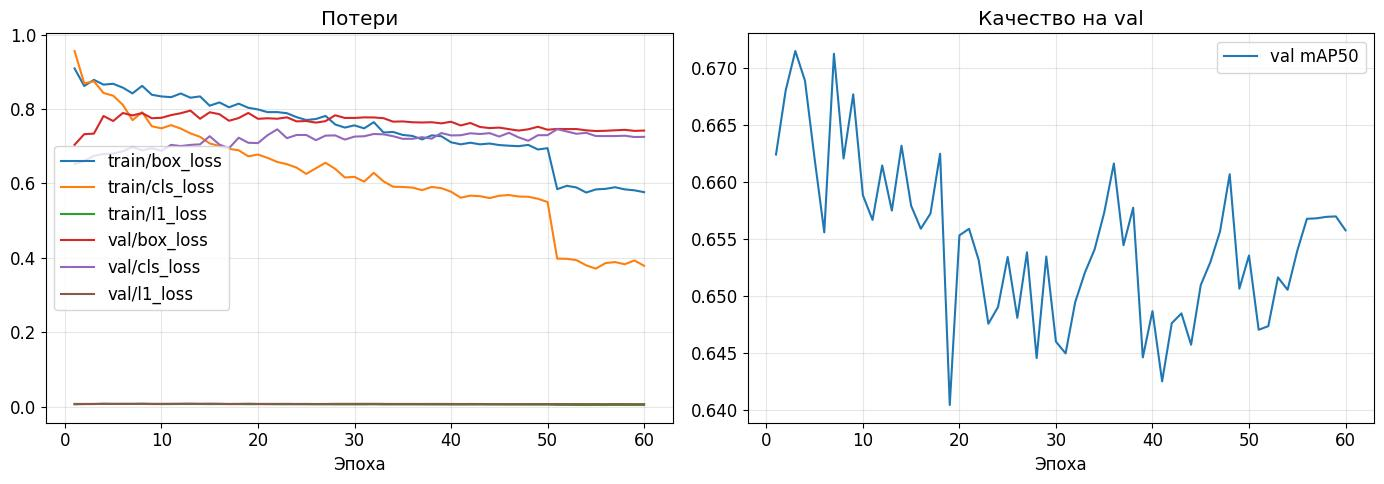

In [34]:
# ваш код
results = read_results(run_dir)
epochs = np.arange(1, len(next(iter(results.values()))) + 1)

loss_cols = [name for name in results if "loss" in name]
map_col = "metrics/mAP50(B)"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in loss_cols:
    axes[0].plot(epochs, results[name], label=name)

axes[0].set_title("Потери")
axes[0].set_xlabel("Эпоха")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, results[map_col], label="val mAP50")
axes[1].set_title("Качество на val")
axes[1].set_xlabel("Эпоха")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

**Ответ:** 

Выводы, рассуждения и мысли по гиперпараметрам частично фиксировал в таблице. Итоговый вариант такой, потому что графики обучения выглядят более адекватно, нет жесткого оверфита, метрики достаточно приличные

Использовал AdamW с lr0=0.00027, т.к. меньший шаг помогает аккуратнее дообучать предобученные веса. Заморозил backbone, чтобы сохранить часть уже выученных признаков. Также оставил mosaic=0.5 и изменения цвета, чтобы модель видела более разные варианты изображений

По финальным кривым train loss стабильно падает, val loss для классификации растет все обучение, а val box loss сначала растет, потом начинает падать, а mAP50 к концу начинает расти после падания в начале

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [35]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

In [36]:
# ваш код
best_val_results = val_metrics(model=best, split="val", name=RUN_NAME)
best_test_results = val_metrics(model=best, split="test", name=RUN_NAME)

best_records_test = predict_records(model=best, recs=records[FINAL_SPLIT])
best_map50_test = evaluate_map50(
    preds=best_records_test, gts=records[FINAL_SPLIT], n_classes=len(CLASSES)
)


per_class = {
    name: {
        "map50": float(best_test_results.box.ap50[i]),
        "map50_95": float(best_test_results.box.maps[i]),
    }
    for i, name in enumerate(CLASSES)
}

FINAL = {
    "map50": best_map50_test[0],
    "map50_95": best_test_results.results_dict['metrics/mAP50-95(B)'],
    "precision": best_test_results.results_dict['metrics/precision(B)'],
    "recall": best_test_results.results_dict['metrics/recall(B)'],
    "per_class": per_class
}

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,477,564 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1657.7±418.0 MB/s, size: 87.5 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 302 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 302/302 105.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.5it/s 4.3s0.2s
                   all        302       1474       0.58      0.657      0.662      0.532
Speed: 0.9ms preprocess, 8.7ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs_hw2/finetune
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,477,564 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1892.0±955.6 MB/s, size: 94.1 KB)
val

In [37]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.6727, 'map50_95': 0.5462, 'precision': 0.6904, 'recall': 0.6061}

**Ответ:**

Confusion matrix показывает, какие классы модель предсказывает вместо других. Ячейки с background показывают лишние предсказания и пропущенные объекты

mAP50-95 обычно ниже mAP50, потому что учитывает более строгие пороги IoU. Разница в значениях mAP50 может быть связана, например, с разным способом интерполяции PR-кривой и обработкой предсказаний

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [38]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    # ваш код
    n, a_dim = a.shape
    m, b_dim = b.shape
    if a_dim != 4:
        raise ValueError("a must be have shape (n,4)")
    if b_dim != 4:
        raise ValueError("b must be have shape (n,4)")
    
    xa1, ya1, xa2, ya2 = a.T
    xb1, yb1, xb2, yb2 = b.T

    x1 = np.maximum(xa1[:, None], xb1[None, :])
    y1 = np.maximum(ya1[:, None], yb1[None, :])
    x2 = np.minimum(xa2[:, None], xb2[None, :])
    y2 = np.minimum(ya2[:, None], yb2[None, :])

    intersection_w = np.maximum(0, x2 - x1)
    intersection_h = np.maximum(0, y2 - y1)
    intersection_area = intersection_w * intersection_h

    a_area = (xa2 - xa1) * (ya2 - ya1)
    b_area = (xb2 - xb1) * (yb2 - yb1)
    union_area = a_area[:, None] + b_area[None, :] - intersection_area

    iou = np.zeros_like(union_area, dtype=np.float32)
    np.divide(intersection_area, union_area, out=iou, where=union_area > 0)
    return iou


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    # ваш код
    pred_boxes = np.asarray(pred["boxes"])
    pred_scores = np.asarray(pred["scores"])
    pred_labels = np.asarray(pred["labels"])
    gt_boxes = np.asarray(gt["boxes"])
    gt_labels = np.asarray(gt["labels"])

    ious = box_iou_np(pred_boxes, gt_boxes)
    categories = ["background"] * len(pred_boxes)
    found_gt = np.zeros(len(gt_boxes), dtype=bool)
    error_gt = np.zeros(len(gt_boxes), dtype=bool)

    order = np.argsort(-pred_scores)

    for pred_idx in order:
        same_class = gt_labels == pred_labels[pred_idx]

        same_candidates = same_class & ~found_gt
        best_same_gt = None
        best_same_iou = -1

        if same_candidates.any():
            same_ious = np.where(same_candidates, ious[pred_idx], -1)
            best_same_gt = np.argmax(same_ious)
            best_same_iou = ious[pred_idx, best_same_gt]

        if best_same_iou >= iou_hit:
            categories[pred_idx] = "tp"
            found_gt[best_same_gt] = True
            continue

        wrong_candidates = ~same_class
        best_wrong_gt = None
        best_wrong_iou = -1

        if wrong_candidates.any():
            wrong_ious = np.where(wrong_candidates, ious[pred_idx], -1)
            best_wrong_gt = np.argmax(wrong_ious)
            best_wrong_iou = ious[pred_idx, best_wrong_gt]

        if best_wrong_iou >= iou_hit:
            categories[pred_idx] = "class"
            error_gt[best_wrong_gt] = True
            continue

        if iou_loc <= best_same_iou < iou_hit:
            categories[pred_idx] = "localization"
            error_gt[best_same_gt] = True

    missed = [
        gt_idx
        for gt_idx in range(len(gt_boxes))
        if not found_gt[gt_idx] and not error_gt[gt_idx]
    ]

    return categories, missed

In [39]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


In [40]:
# ваш код
val_recs = records["val"]
val_preds = predict_records(best, val_recs, conf=CONF_ERRORS)

ERRORS = {category: 0 for category in ERROR_TYPES}
by_class = {category: Counter() for category in ERROR_TYPES}
error_examples = []

for image_idx, (rec, pred) in enumerate(zip(val_recs, val_preds)):
    gt = {"boxes": rec["boxes"], "labels": rec["labels"]}
    categories, missed = categorize_predictions(pred, gt)

    for pred_idx, category in enumerate(categories):
        ERRORS[category] += 1
        class_idx = int(pred["labels"][pred_idx])
        by_class[category][class_idx] += 1

        if category != "tp":
            error_examples.append((image_idx, category, pred_idx))

    for gt_idx in missed:
        ERRORS["missed"] += 1
        class_idx = int(rec["labels"][gt_idx])
        by_class["missed"][class_idx] += 1
        error_examples.append((image_idx, "missed", gt_idx))


total = sum(ERRORS.values())

print("Категории:")
for category, count in ERRORS.items():
    share = count / total if total else 0
    print(f"{category}: {count} ({share:.1%})")

print("\nОшибки по классам:")
for category in ERROR_TYPES:
    class_counts = [
        f"{CLASSES[class_idx]}: {count}"
        for class_idx, count in sorted(by_class[category].items())
    ]

    if class_counts:
        print(f"{category}: " + ", ".join(class_counts))

Категории:
tp: 1277 (72.4%)
class: 20 (1.1%)
localization: 49 (2.8%)
background: 259 (14.7%)
missed: 158 (9.0%)

Ошибки по классам:
tp: backpack: 6, bench: 3, bicycle: 21, bird: 13, boat: 4, book: 2, bottle: 19, bowl: 3, bus: 3, car: 56, cell phone: 1, chair: 40, cup: 16, dog: 28, frisbee: 1, handbag: 19, horse: 8, laptop: 2, motorcycle: 6, person: 972, potted plant: 4, skateboard: 4, sports ball: 8, suitcase: 1, surfboard: 1, traffic light: 5, truck: 6, tv: 1, umbrella: 18, wine glass: 6
class: backpack: 2, bicycle: 3, bowl: 1, car: 2, couch: 2, dog: 2, handbag: 3, person: 1, truck: 3, wine glass: 1
localization: backpack: 2, bicycle: 1, boat: 2, car: 5, cell phone: 1, chair: 1, dog: 1, handbag: 4, person: 32
background: backpack: 11, bicycle: 8, boat: 4, book: 3, bottle: 12, bus: 1, car: 8, chair: 16, couch: 1, cup: 4, dog: 1, frisbee: 1, handbag: 10, person: 155, potted plant: 6, skateboard: 1, sports ball: 3, suitcase: 1, traffic light: 1, truck: 6, tv: 1, umbrella: 4, wine glass: 

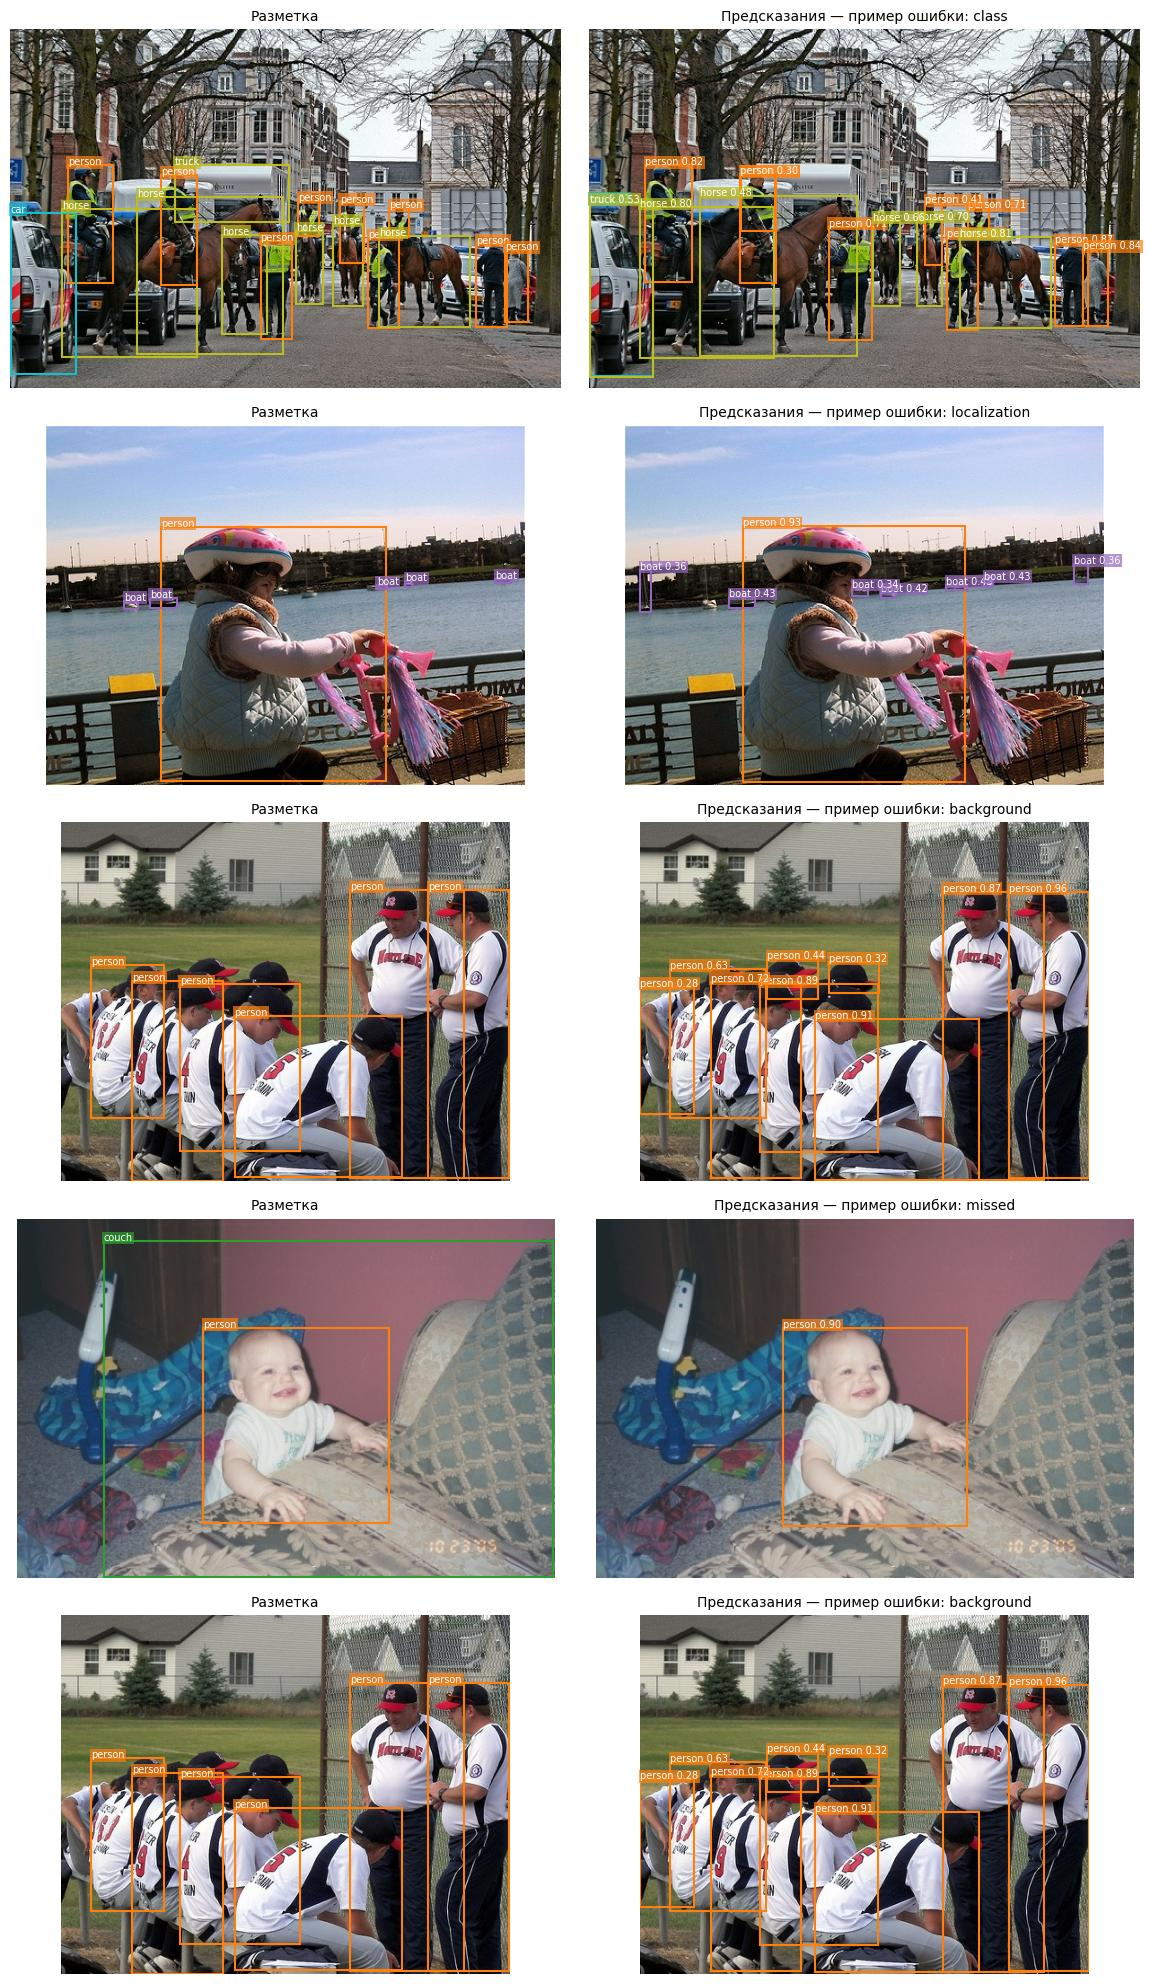

In [41]:
examples = []

for category in ("class", "localization", "background", "missed"):
    for example in error_examples:
        if example[1] == category:
            examples.append(example)
            break

for example in error_examples:
    if example not in examples and len(examples) < 5:
        examples.append(example)


if examples:
    fig, axes = plt.subplots(
        len(examples), 2,
        figsize=(12, 4 * len(examples)),
        squeeze=False
    )

    for row, (image_idx, category, _) in enumerate(examples):
        rec = val_recs[image_idx]
        pred = val_preds[image_idx]
        image = np.asarray(Image.open(rec["image"]).convert("RGB"))

        draw_boxes(
            axes[row, 0],
            image,
            rec["boxes"],
            rec["labels"],
            CLASSES,
            title="Разметка",
        )
        draw_boxes(
            axes[row, 1],
            image,
            pred["boxes"],
            pred["labels"],
            CLASSES,
            scores=pred["scores"],
            title=f"Предсказания — пример ошибки: {category}",
        )

    plt.tight_layout()
    plt.show()
else:
    print("Ошибок для визуализации не оказалось")

**Ответ:**

Чаще всего встретилась категория person с большим кол-вом ошибок (это связано банально с тем, что этого класса больше всего в датасете). На примерах видно, что мы часто пропускаем людей в толпе и в скоплениях объектов. Для уменьшения таких ошибок можно попробовать пороги уверенности менять, чтобы калибровать precision/recall, также использовать mixup

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [42]:
# ваш код
metrics_s = val_metrics(best, "val", "ablation_s_val")
time_s = RUN_TIMES["train"]

set_seed(SEED)
_, time_n, run_n = train_yolo("ablation_n", weights="yolo26n.pt", **TRAIN_ARGS)

model_n = YOLO(run_n / "weights" / "best.pt")
metrics_n = val_metrics(model_n, "val", "ablation_n_val")

RUN_TIMES["ablation_n"] = time_n
ABLATION = {
    "change": "model size: n vs s",
    "s": {
        "map50": float(metrics_s.box.map50),
        "map50_95": float(metrics_s.box.map),
        "train_time_sec": float(time_s),
    },
    "n": {
        "map50": float(metrics_n.box.map50),
        "map50_95": float(metrics_n.box.map),
        "train_time_sec": float(time_n),
    },
}

for name in ("s", "n"):
    result = ABLATION[name]
    print(
        f"{name} | {result['map50']:.4f} | "
        f"{result['map50_95']:.4f} | {result['train_time_sec']}"
    )

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,477,564 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2547.8±646.1 MB/s, size: 96.5 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 302 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 302/302 70.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 4.5it/s 4.2s0.2s
                   all        302       1474       0.58      0.657      0.662      0.532
Speed: 0.8ms preprocess, 8.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /kaggle/working/runs_hw2/ablation_s_val
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=Non

**Ответ:**

У s mAP50 получился 0.6624, mAP50-95 - 0.5322, время обучения - 1123 секунд. У n - 0.6299, 0.4690, 813 соответственно

При переходе к n качество улучшилось, причем для mAP50-95 достаточно сильно, но время обучения выросло почти в полтора раза

Я бы выбрал s, потому что качество растет достаточно сильно при  приросте не таком катастрафическом росте времени обучения. Но сравнение сделал с одним seed, поэтому небольшая разница может зависеть от случайности

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

Я взял датасет для детекции из 15к картинок, выбрал из него подвыборку из 2000 изображений и дообучил YOLO26s

До дообучения COCO модель получила mAP50 0.7104, после - 0.6624 на том же test. Эвристика - 0.000161. При сравнении n и s на val видно, что n быстрее обучается, но разница в качестве все равно позволяет более уверенно выбрать s, т.к. скорость обуния не очень падает у s

Делал много экспериментировал с прогонами, с разными параметрами, но не получилось добиться результата лучше, чем чекпоинт. Все обучал и тестировал на одном сиде, что не дает утверждать однозначных результатов

Дальше я бы проверил результат на нескольких сидах, при разных разбиениях выборок, покрутил бы параметры сплитов. Также поисследовал, какие аугментации дают прирост метрик

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [43]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


In [44]:
from IPython.display import FileLink

results_dir = Path("/kaggle/working/hw2_main_results")
results_dir.mkdir(exist_ok=True)

shutil.copytree("artifacts", results_dir / "artifacts", dirs_exist_ok=True)
shutil.copytree(run_dir, results_dir / "training_run", dirs_exist_ok=True)

archive_path = shutil.make_archive(
    "/kaggle/working/hw2_main_results",
    "zip",
    root_dir=results_dir,
)

print(archive_path)
FileLink("hw2_main_results.zip")

/kaggle/working/hw2_main_results.zip


/kaggle/working/hw2_main_results.zip

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [45]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [46]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [47]:
if '6.3' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [48]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [49]:
if '6.5' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 